In [ ]:
from google.colab import drive
# Force a clean remount attempt after restarting your runtime
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/work_project/Dhaka.csv')
df.head()

,Unnamed: 0,Station,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,153400,Dhaka,1961,1,1,0.5,0.4,80.0,21.5
1,153401,Dhaka,1961,1,2,1.0,5.9,76.0,22.2
2,153402,Dhaka,1961,1,3,0.0,4.2,75.0,23.1
3,153403,Dhaka,1961,1,4,0.0,6.8,74.0,19.8
4,153404,Dhaka,1961,1,5,0.0,10.0,68.0,16.6


In [ ]:
df.drop(columns=['Unnamed: 0','Station'], inplace=True)
df.head()

,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
0,1961,1,1,0.5,0.4,80.0,21.5
1,1961,1,2,1.0,5.9,76.0,22.2
2,1961,1,3,0.0,4.2,75.0,23.1
3,1961,1,4,0.0,6.8,74.0,19.8
4,1961,1,5,0.0,10.0,68.0,16.6


In [ ]:
df.isnull().sum()

,0
Year,0
Month,0
Day,0
Rainfall,0
Sunshine,0
Humidity,0
Temperature,0


In [ ]:
# Count total duplicate rows
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Year,Month,Day,Rainfall,Sunshine,Humidity,Temperature
count,23010.000000,23010.000000,23010.000000,23010.000000,23010.000000,23010.000000,23010.000000
mean,1992.000000,6.523077,15.729205,5.507048,6.518466,74.615072,25.835671
std,18.184064,3.448738,8.800101,15.588238,3.247169,10.973908,4.118754
min,1961.000000,1.000000,1.000000,0.000000,0.000000,29.000000,10.400000
25%,1976.000000,4.000000,8.000000,0.000000,4.300000,68.000000,22.900000
50%,1992.000000,7.000000,16.000000,0.000000,7.400000,76.000000,27.200000
75%,2008.000000,10.000000,23.000000,2.000000,9.100000,83.000000,29.000000
max,2023.000000,12.000000,31.000000,341.000000,13.800000,100.000000,37.800000


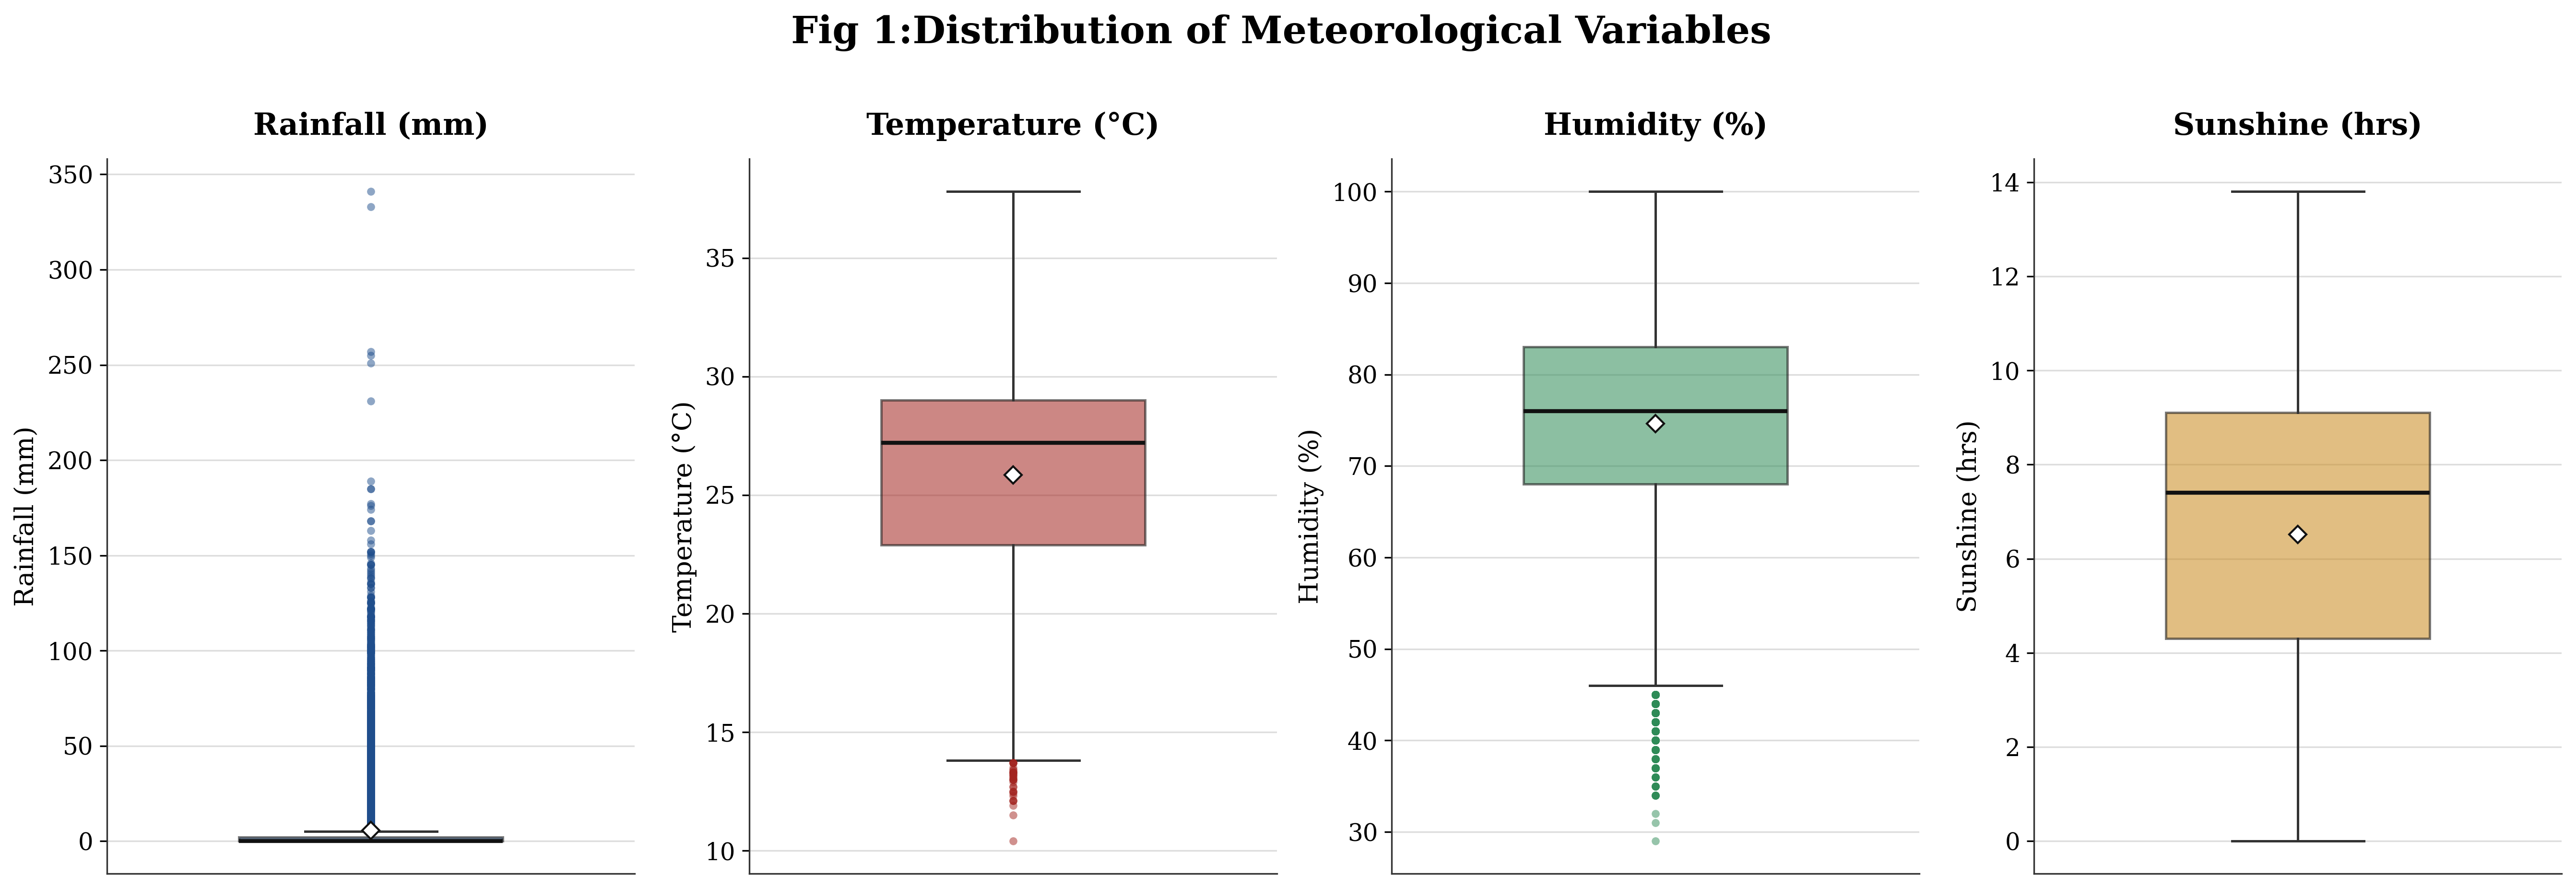

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==========================================================
# Publication Style
# ==========================================================
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

mpl.rcParams['axes.titlesize'] = 17
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12

mpl.rcParams['axes.edgecolor'] = '#333333'
mpl.rcParams['axes.linewidth'] = 0.8
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['savefig.dpi'] = 600



# ==========================================================
# Variables to Plot
# ==========================================================
variables = ['Rainfall', 'Temperature', 'Humidity', 'Sunshine']

pretty = {
    'Rainfall': 'Rainfall (mm)',
    'Temperature': 'Temperature (°C)',
    'Humidity': 'Humidity (%)',
    'Sunshine': 'Sunshine (hrs)'
}

# Box + accent colors (one per variable)
colors = ['#1f4e8c', '#a3241f', '#2e8b57', '#c98a1c']


# ==========================================================
# Figure
# ==========================================================
fig, axes = plt.subplots(
    1, len(variables),
    figsize=(18, 6)
)

for ax, var, color in zip(axes, variables, colors):

    box = ax.boxplot(
        df[var].dropna(),
        patch_artist=True,
        widths=0.5,
        showmeans=True,
        meanprops={
            'marker': 'D',
            'markerfacecolor': 'white',
            'markeredgecolor': '#111111',
            'markersize': 6
        },
        medianprops={
            'color': '#111111',
            'linewidth': 2
        },
        whiskerprops={
            'color': '#333333',
            'linewidth': 1.2
        },
        capprops={
            'color': '#333333',
            'linewidth': 1.2
        },
        flierprops={
            'marker': 'o',
            'markerfacecolor': color,
            'markeredgecolor': 'none',
            'markersize': 4,
            'alpha': 0.5
        }
    )

    # Fill box
    for patch in box['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.55)
        patch.set_edgecolor('#111111')
        patch.set_linewidth(1.2)

    # ------------------------------------------------------
    # Axis Styling
    # ------------------------------------------------------
    ax.set_title(pretty[var], fontsize=15, fontweight='bold', pad=12)
    ax.set_xticks([])
    ax.set_ylabel(pretty[var], fontsize=13)

    ax.grid(axis='y', color='#dddddd', linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)

    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)


# ==========================================================
# Main Title
# ==========================================================
fig.suptitle(
    "Fig 1:Distribution of Meteorological Variables ",
    fontsize=19,
    fontweight='bold',
    y=1.02
)

fig.tight_layout()


# ==========================================================
# Save Figure
# ==========================================================
plt.savefig(
    "Meteorological_Boxplots.png",
    dpi=600,
    bbox_inches='tight',
    facecolor='white'
)

plt.show()

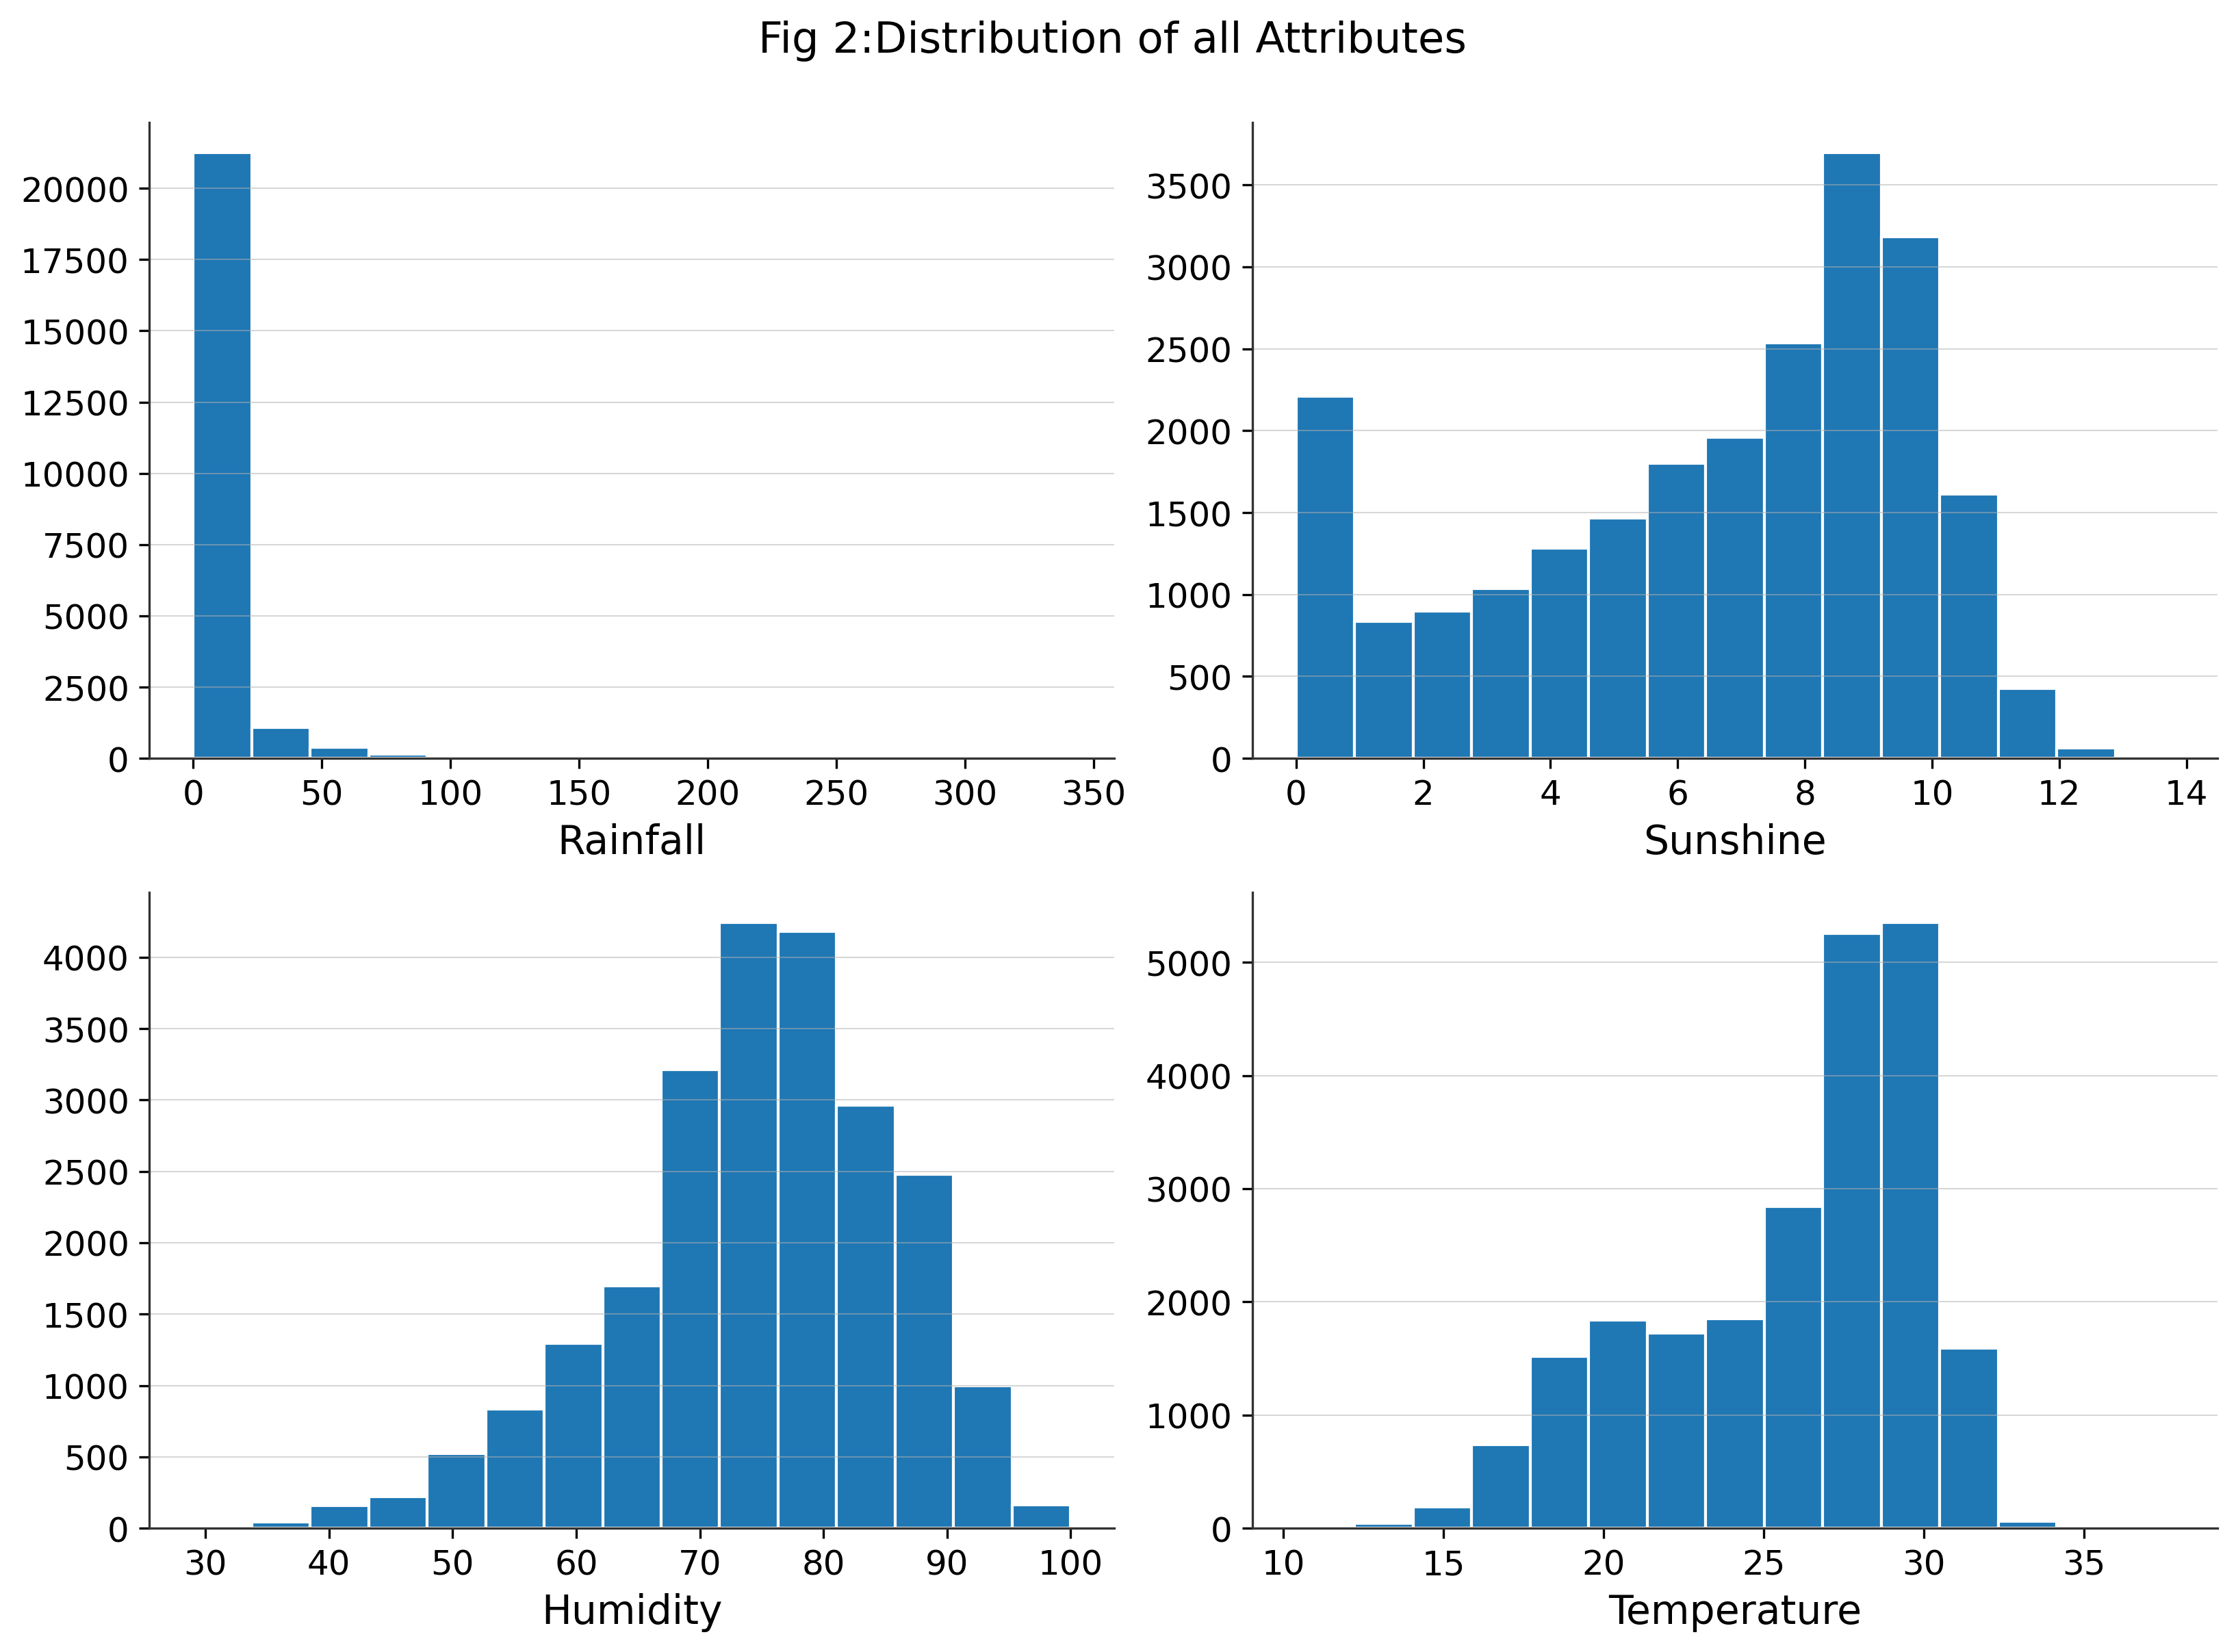

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

 # adjust path as needed

params = ['Rainfall', 'Sunshine', 'Humidity', 'Temperature']

mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.size'] = 10

fig, axes = plt.subplots(2, 2, figsize=(11, 8), dpi=300)
axes = axes.flatten()

for ax, param in zip(axes, params):
    ax.hist(df[param].dropna(), bins=15, color='#1f77b4', edgecolor='white')
    ax.set_xlabel(param)
    # ax.set_ylabel('RainToday')  # target label, change if using a different target
    ax.grid(axis='y', linestyle='-', linewidth=0.5, alpha=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Fig 2:Distribution of all Attributes ', fontsize=15, y=1.0)
plt.tight_layout()
plt.savefig('chittagong_dist_vs_target.png', dpi=300, bbox_inches='tight')
plt.show()

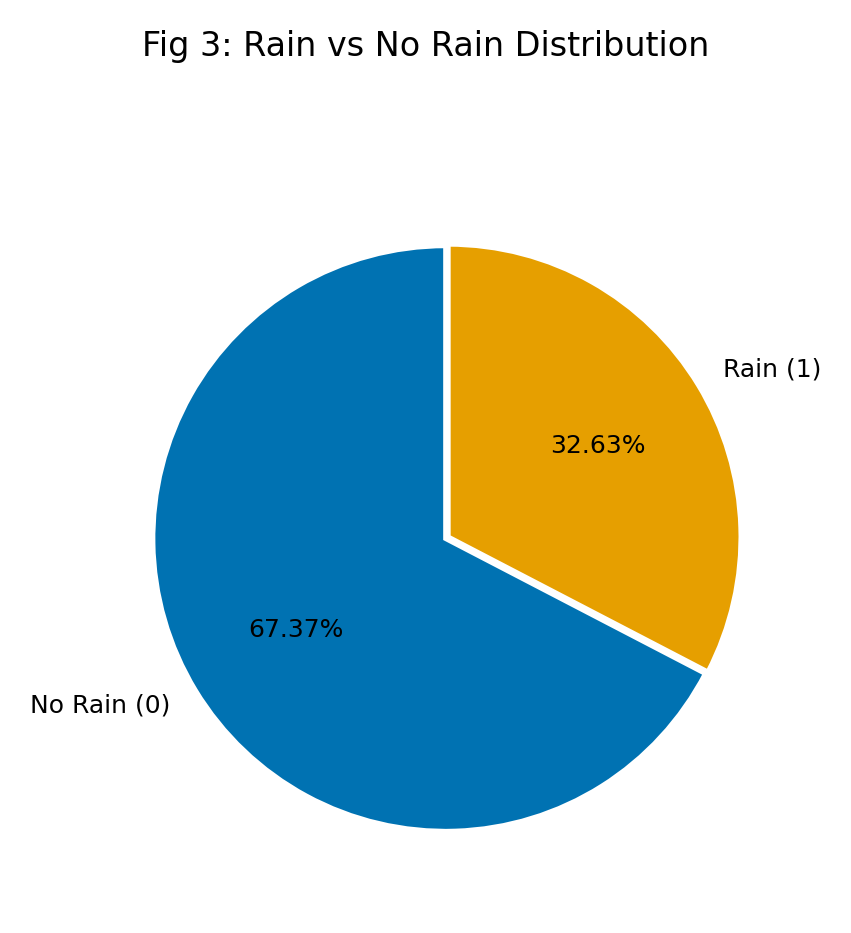

In [ ]:
import matplotlib.pyplot as plt

df['RainToday'] = df['Rainfall'].apply(lambda x: 'Yes' if x > 0 else 'No')

# Calculate the counts of 'Rain' and 'No Rain' from the 'RainToday' column
rain_counts = df['RainToday'].value_counts().sort_index()

# Define the figure and axis explicitly to make suptitle work smoothly
fig, ax = plt.subplots(figsize=(3, 3))

ax.pie(
    rain_counts,
    labels=['No Rain (0)', 'Rain (1)'],
    colors=['#0072B2', '#E69F00'],
    autopct='%1.2f%%',
    startangle=90,
    explode=(0.01, 0),
    wedgeprops={
        'edgecolor': 'white',
        'linewidth': 1.2
    },
    textprops={
        'fontsize': 6
    }
)

fig.suptitle('Fig 3: Rain vs No Rain Distribution', fontsize=8, y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import zscore

# Select only the numeric columns to compute Z-scores
numeric_cols = ["Rainfall", "Sunshine", "Humidity", "Temperature"]
z_scores = df[numeric_cols].apply(zscore)

# Count how many data points have an absolute Z-score greater than 3 (outliers)
(z_scores.abs() > 3).sum()

,0
Rainfall,532
Sunshine,0
Humidity,122
Temperature,30


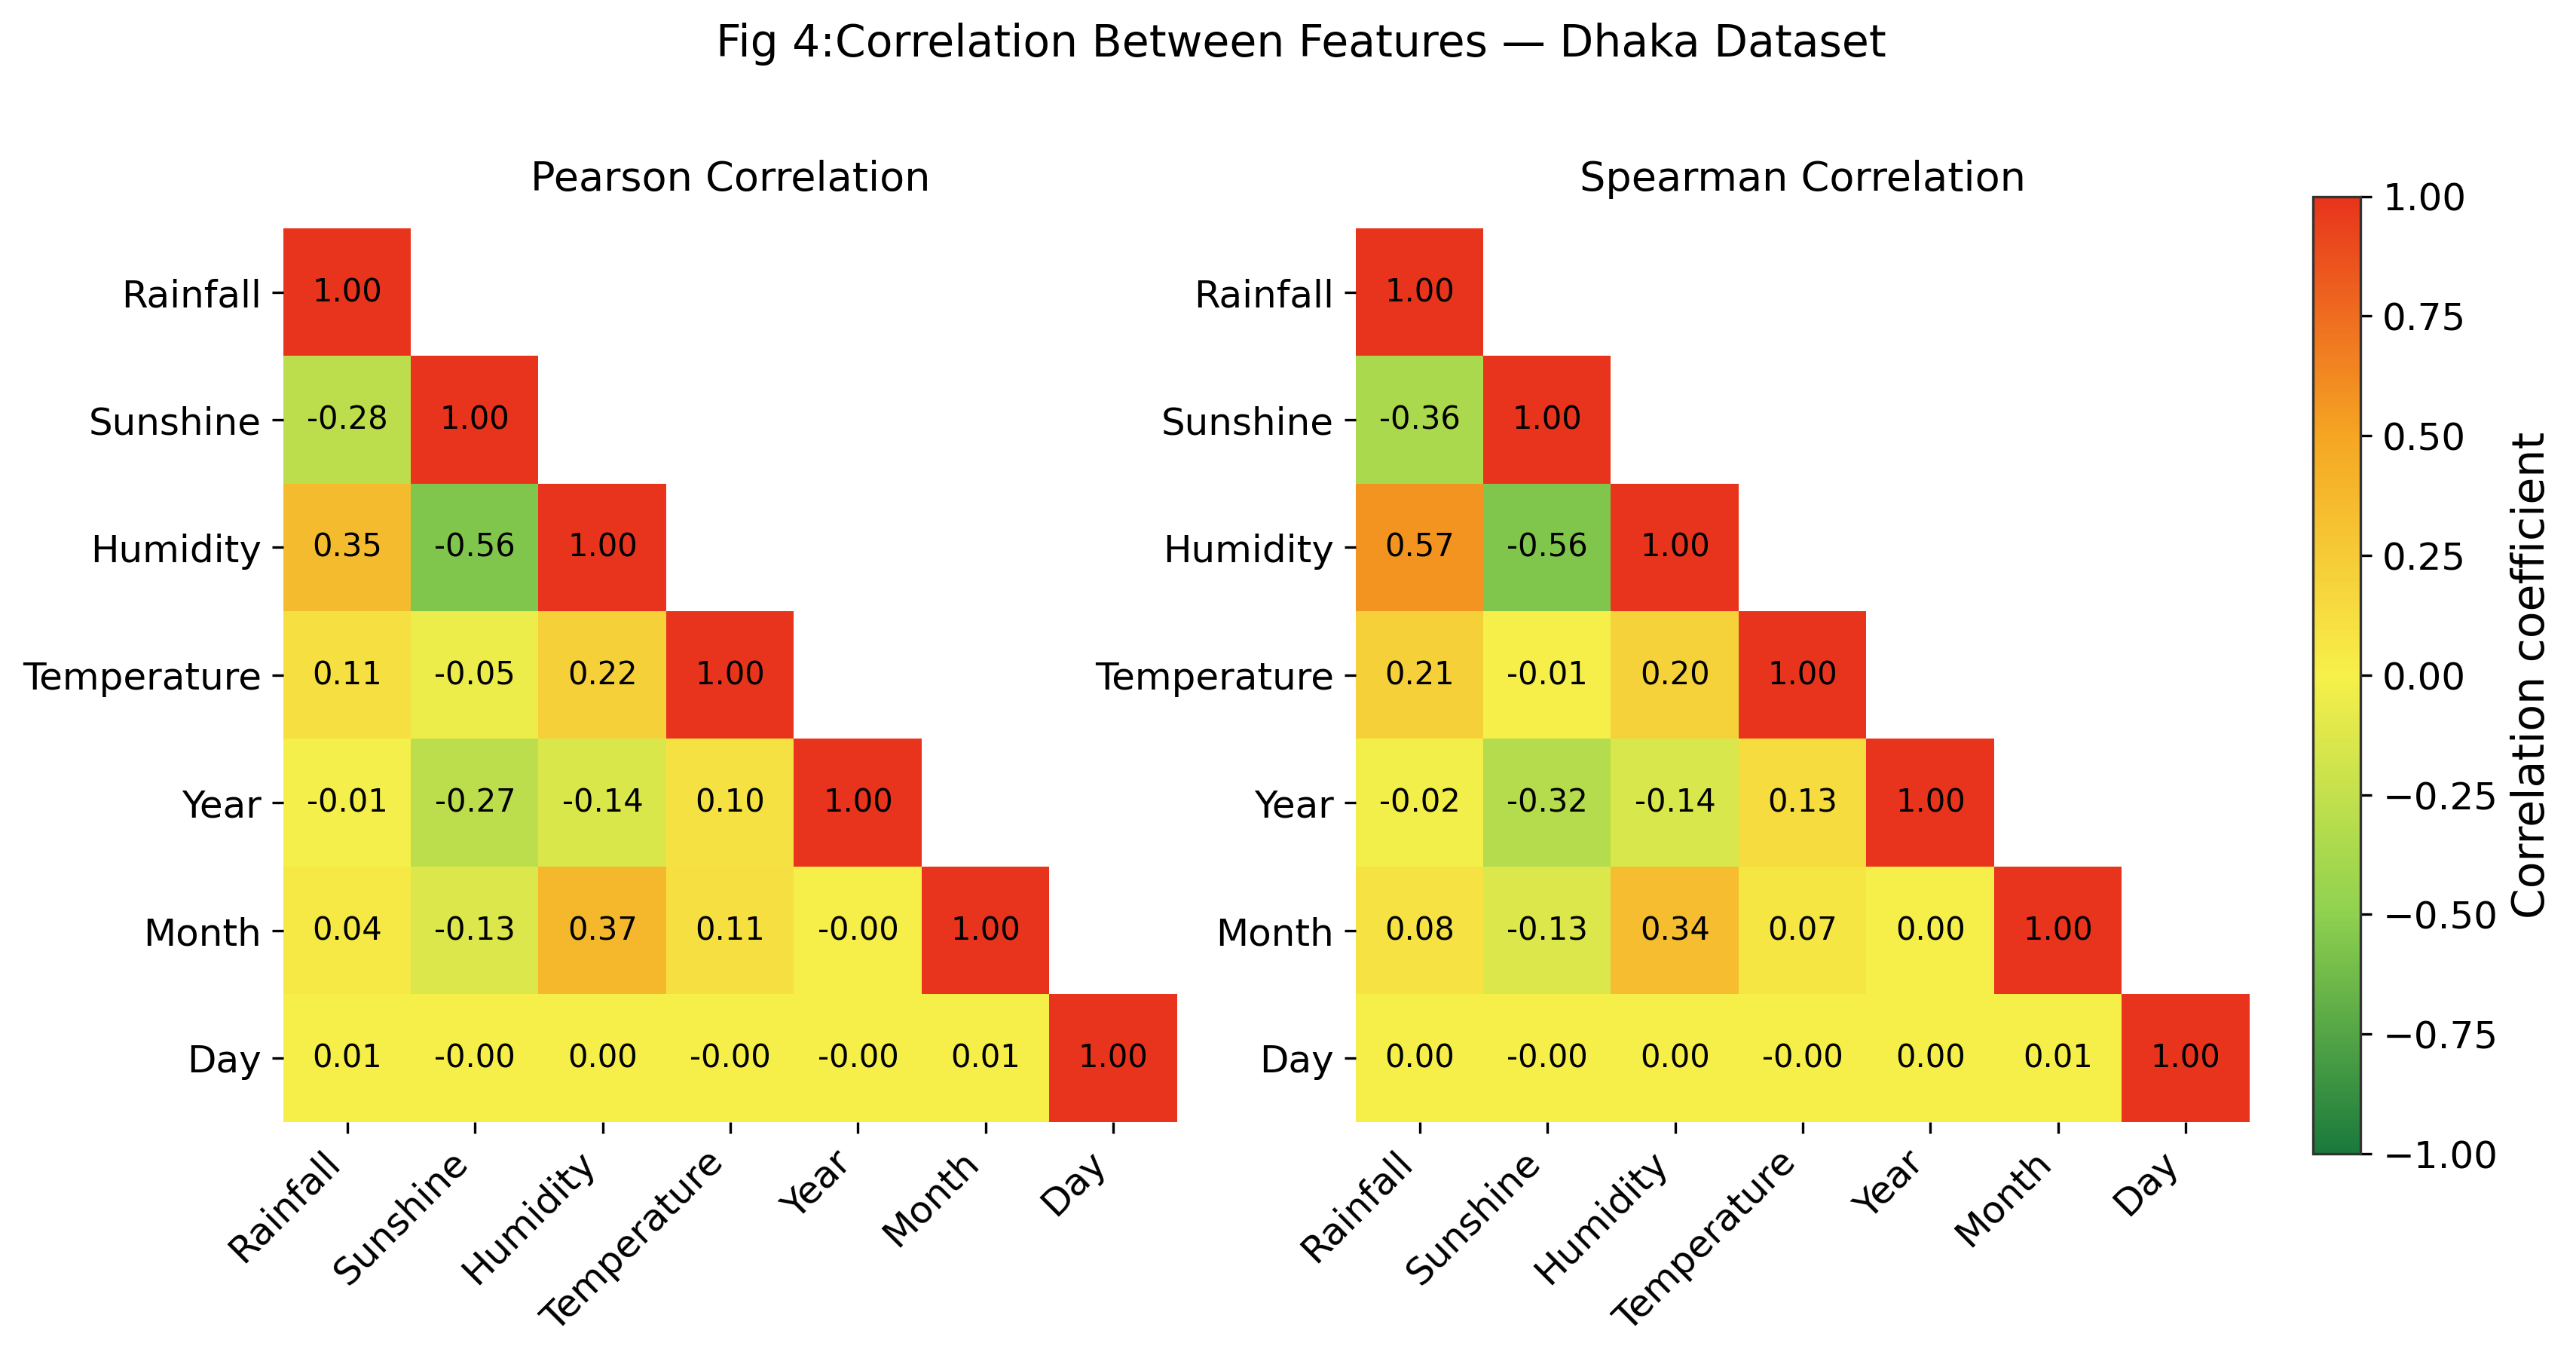

In [ ]:
"""
Pearson & Spearman Correlation Heatmaps -- Chittagong dataset
(Rainfall, Sunshine, Humidity, Temperature)

Style matches the reference figure: lower-triangle heatmap,
red-yellow-green diverging colormap, annotated correlation values.

Output: correlation_heatmaps.png
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap



features = ["Rainfall", "Sunshine", "Humidity", "Temperature","Year","Month","Day"]
data = df[features]

pearson_corr  = data.corr(method="pearson")
spearman_corr = data.corr(method="spearman")

# ------------------------------------------------------------------
# 2. Red -> Yellow -> Green diverging colormap (like reference figure)
# ------------------------------------------------------------------
cmap = LinearSegmentedColormap.from_list(
    "RdYlGn_r_custom",
    ["#1a7a3c", "#8fd14f", "#f7f04a", "#f5a623", "#e8341c"],
    N=256,
)

def plot_triangular_heatmap(ax, corr, title):
    n = len(corr)
    mask = np.triu(np.ones((n, n), dtype=bool), k=1)  # hide upper triangle
    corr_masked = np.ma.array(corr.values, mask=mask)

    im = ax.imshow(corr_masked, cmap=cmap, vmin=-1, vmax=1)

    # annotate cells
    for i in range(n):
        for j in range(n):
            if j <= i:
                val = corr.values[i, j]
                ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                         fontsize=10, color="black")

    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticklabels(corr.columns)
    ax.set_title(title, fontsize=13, pad=12)

    # remove upper-right ticks/spines look cleaner
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.grid(False)

    return im

# ------------------------------------------------------------------
# 3. Plot side by side
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

im1 = plot_triangular_heatmap(axes[0], pearson_corr,  "Pearson Correlation")
im2 = plot_triangular_heatmap(axes[1], spearman_corr, "Spearman Correlation")

# single shared colorbar
cbar = fig.colorbar(im2, ax=axes, orientation="vertical",
                     fraction=0.035, pad=0.03)
cbar.set_label("Correlation coefficient")

fig.suptitle("Fig 4:Correlation Between Features — Dhaka Dataset",
             fontsize=14, y=1.02)

fig.savefig("correlation_heatmaps.png", dpi=300, bbox_inches="tight",
            facecolor="white")

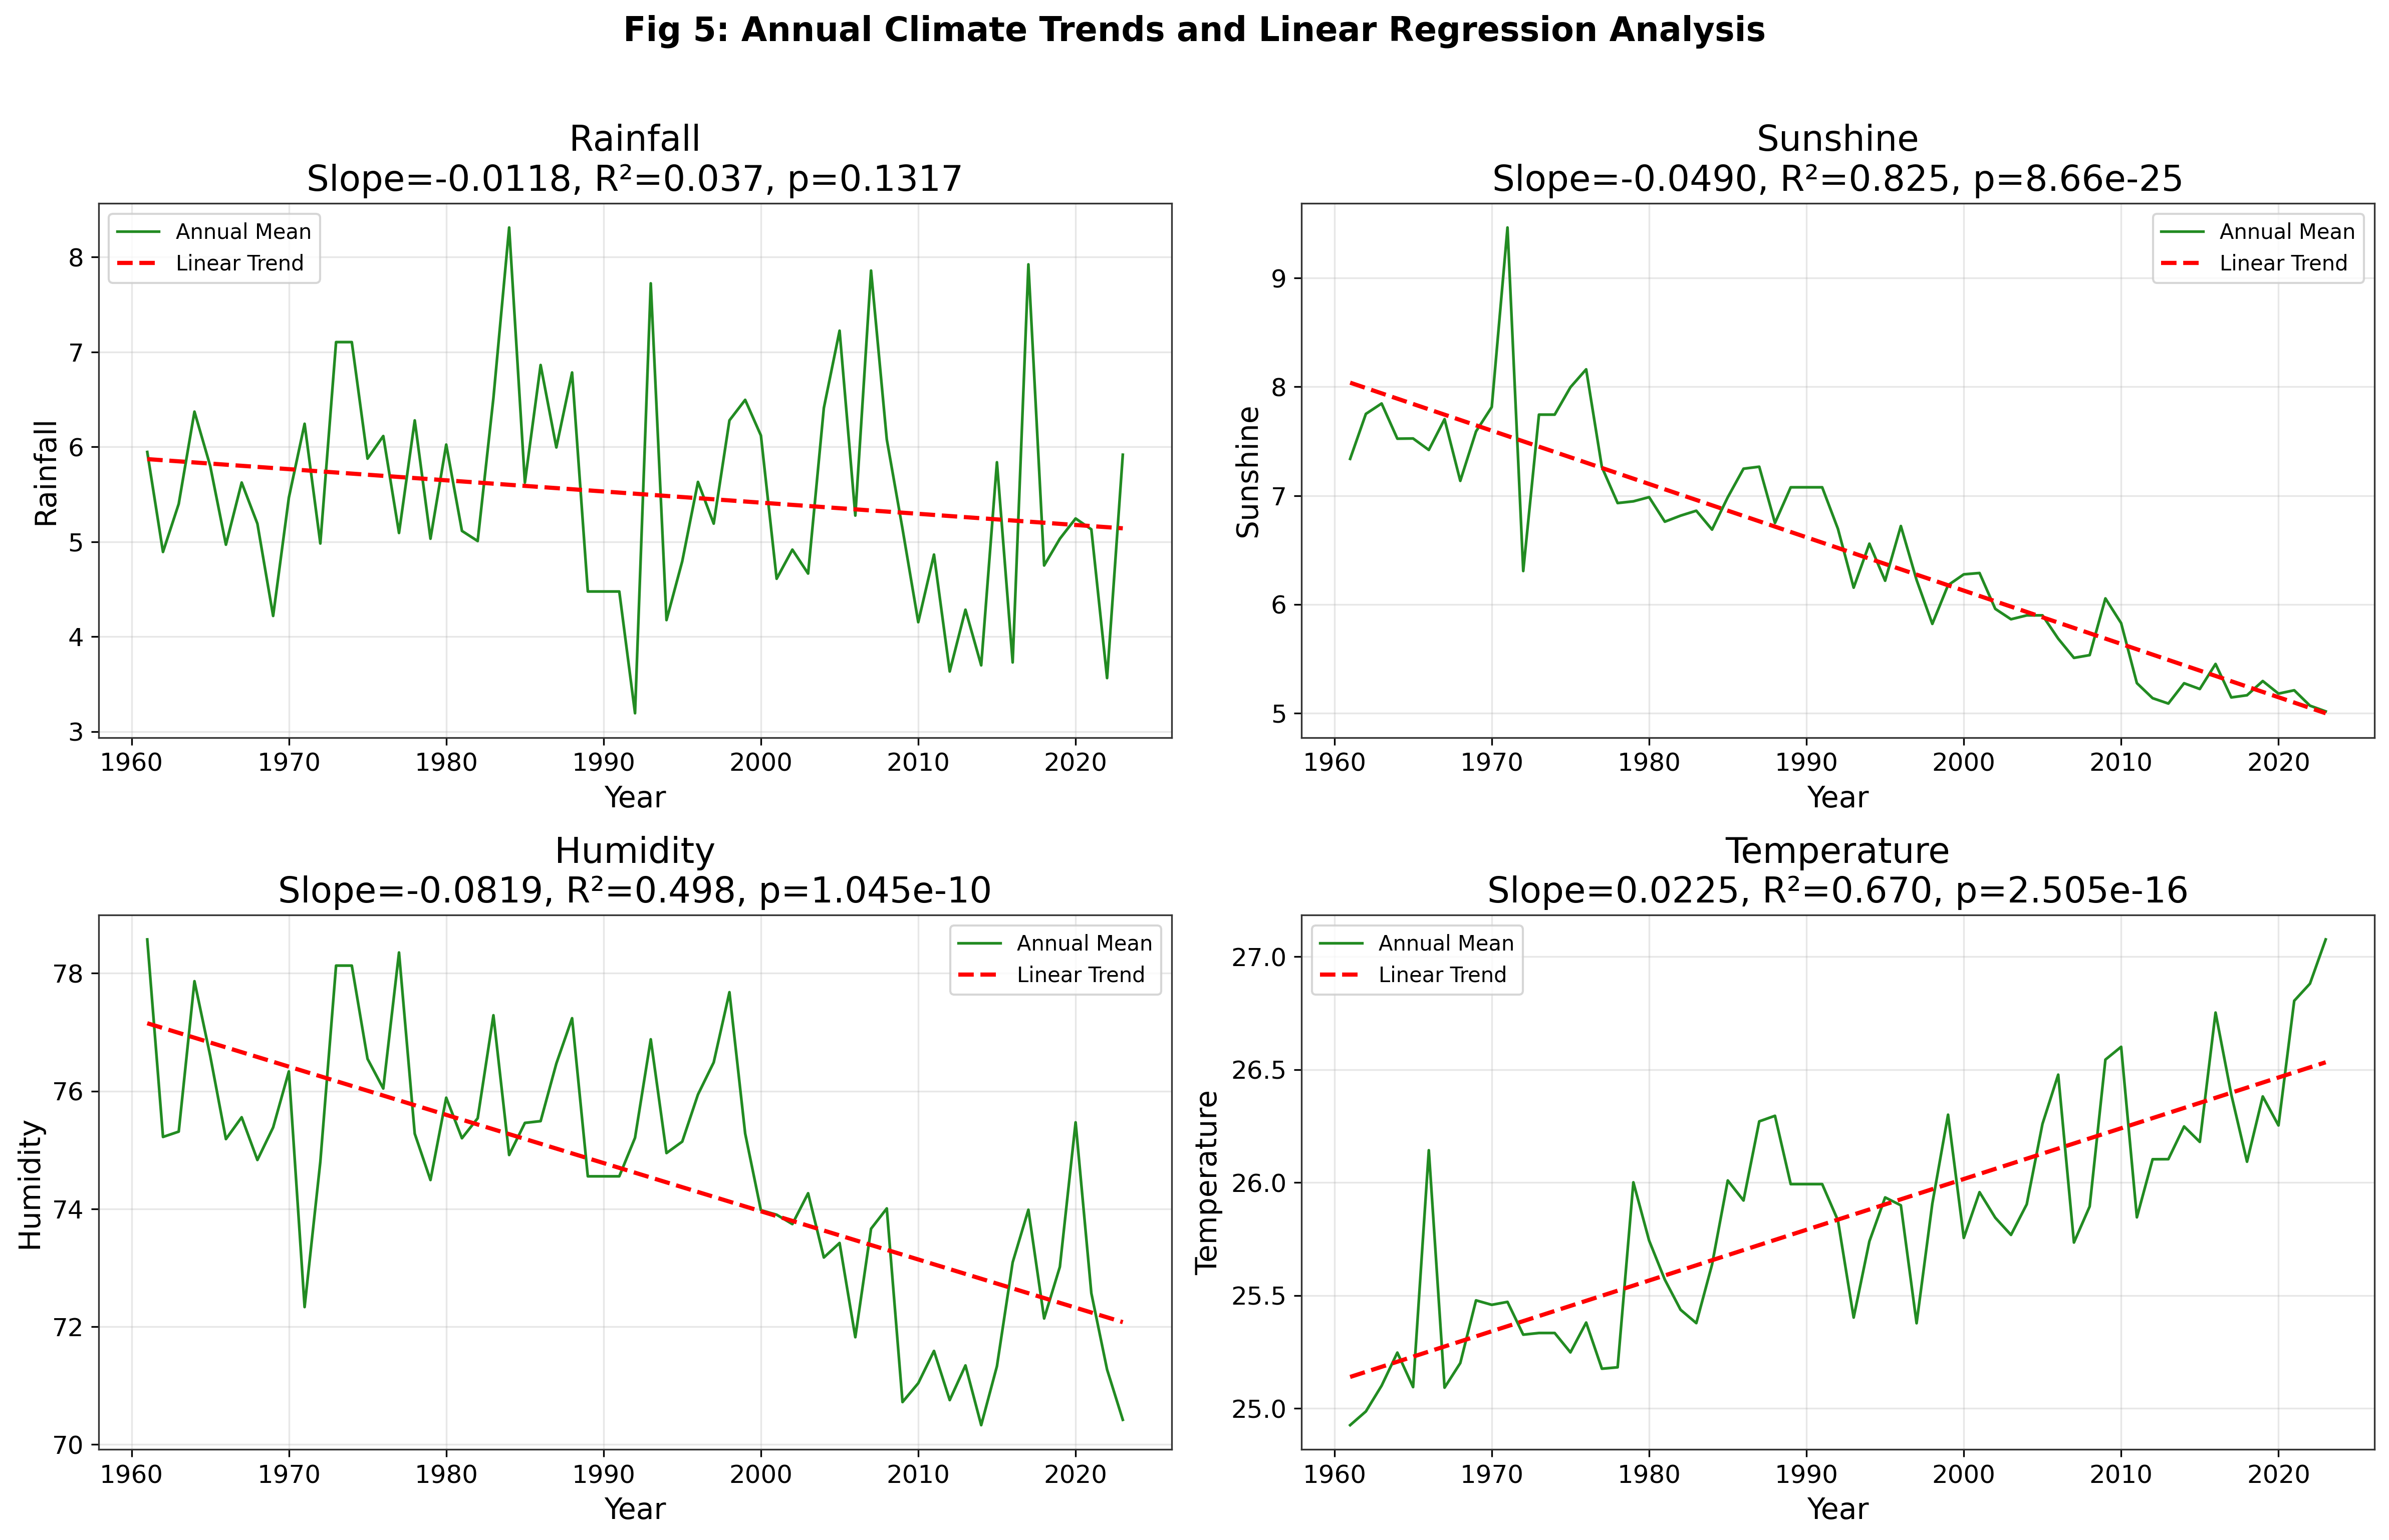

CLIMATE TREND STATISTICS:


,Variable,Slope_per_year,R_squared,P_value,Trend,Significance
0,Rainfall,-0.01176,0.03685,0.13174,Decreasing,Not significant
1,Sunshine,-0.04902,0.82530,0.00000,Decreasing,Significant
2,Humidity,-0.08185,0.49817,0.00000,Decreasing,Significant
3,Temperature,0.02248,0.67017,0.00000,Increasing,Significant


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
from IPython.display import display

# 1. Select climate variables
cols = ["Rainfall", "Sunshine", "Humidity", "Temperature"]

# 2. Calculate annual mean by grouping by Year
annual_data = df.groupby("Year")[cols].mean()
annual_data.index.name = "Year"

# 3. Create subplots
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
trend_results = []

for ax, col in zip(axes.flatten(), cols):

    data = annual_data[col].dropna()
    x = data.index.to_numpy(dtype=float)
    y = data.to_numpy(dtype=float)

    # Linear regression
    result = linregress(x, y)
    trend_line = result.slope * x + result.intercept

    # Plot annual values and trend line
    ax.plot(x, y, color="forestgreen",
            linewidth=1.3, label="Annual Mean")

    ax.plot(x, trend_line, color="red",
            linestyle="--", linewidth=2,
            label="Linear Trend")

    ax.set_title(
        f"{col}\nSlope={result.slope:.4f}, "
        f"R²={result.rvalue**2:.3f}, "
        f"p={result.pvalue:.4g}"
    )
    ax.set_xlabel("Year")
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)
    ax.legend()

    # Store trend statistics
    trend_results.append({
        "Variable": col,
        "Slope_per_year": result.slope,
        "R_squared": result.rvalue**2,
        "P_value": result.pvalue,
        "Trend": (
            "Increasing" if result.slope > 0
            else "Decreasing" if result.slope < 0
            else "No change"
        ),
        "Significance": (
            "Significant" if result.pvalue < 0.05
            else "Not significant"
        )
    })

# Add overall title for the entire figure grid
fig.suptitle('Fig 5: Annual Climate Trends and Linear Regression Analysis', fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
plt.show()

# 5. Display trend statistics
print("CLIMATE TREND STATISTICS:")
trend_table = pd.DataFrame(trend_results)
display(trend_table.round(5))

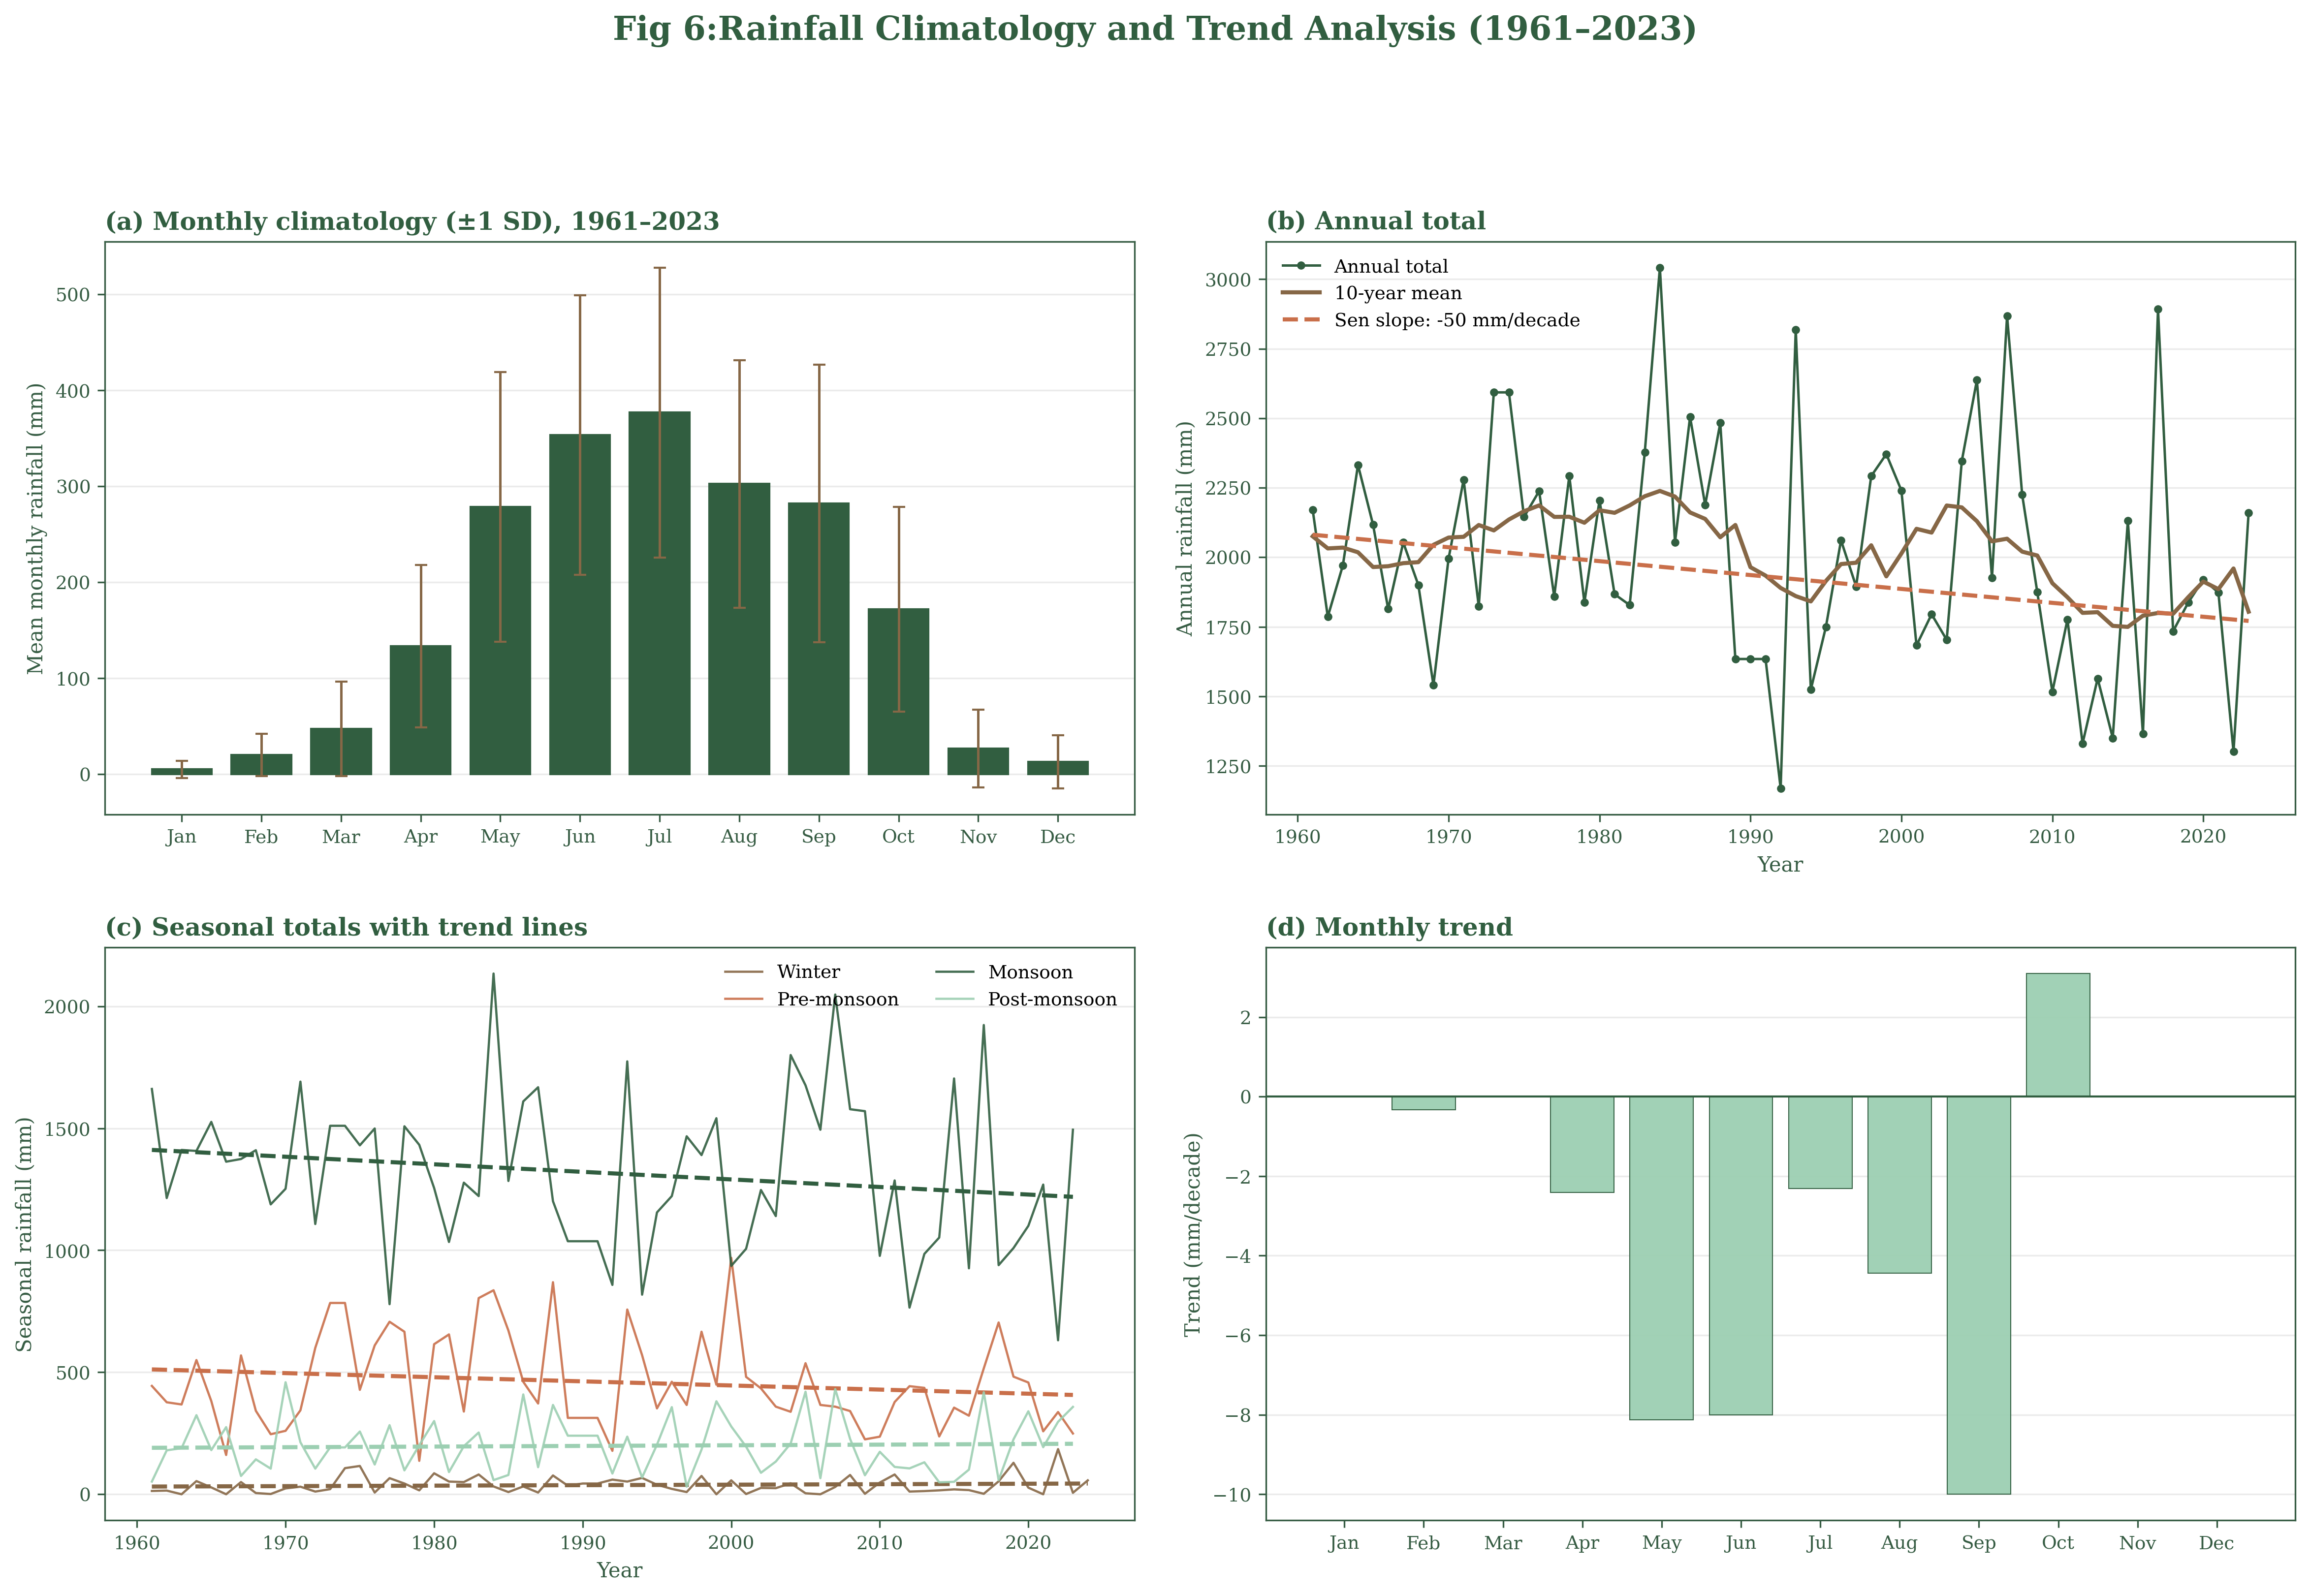

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import linregress, theilslopes, kendalltau

# # ---------------------------------------
# # 1. Prepare data
# # ---------------------------------------
# Ensure df has a DatetimeIndex for resampling
temp_df = df.copy()
temp_df["Date"] = pd.to_datetime(temp_df[["Year", "Month", "Day"]])
temp_df = temp_df.set_index("Date")

# Monthly totals
monthly = temp_df["Rainfall"].resample("MS").sum()

# Annual totals
annual = monthly.groupby(monthly.index.year).sum()
annual.index = annual.index.astype(int)

# Monthly climatology: average monthly total across years
month_clim = monthly.groupby(monthly.index.month)
clim_mean = month_clim.mean()
clim_sd = month_clim.std()

# ---------------------------------------
# 2. Seasonal rainfall totals
# DJF: Winter, MAM: Pre-monsoon,
# JJAS: Monsoon, ON: Post-monsoon
# ---------------------------------------
monthly_df = monthly.rename("Rainfall").to_frame()
monthly_df["Year"] = monthly_df.index.year
monthly_df["Month"] = monthly_df.index.month

def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Pre-monsoon"
    elif month in [6, 7, 8, 9]:
        return "Monsoon"
    else:
        return "Post-monsoon"

monthly_df["Season"] = monthly_df["Month"].apply(get_season)

# Assign December to the following winter year
monthly_df["Season_Year"] = (
    monthly_df["Year"]
    + (monthly_df["Month"] == 12).astype(int)
)

seasonal = monthly_df.groupby(
    ["Season_Year", "Season"]
)["Rainfall"].sum().unstack()

season_order = [
    "Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"
]

# ---------------------------------------
# 3. Plot styling
# ---------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.edgecolor": "#365C43",
    "axes.labelcolor": "#365C43",
    "xtick.color": "#365C43",
    "ytick.color": "#365C43",
})

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
ax1, ax2, ax3, ax4 = axes.flatten()

green = "#315E40"
orange = "#C96F4A"
brown = "#866746"
mint = "#9CCFB2"

# ---------------------------------------
# (a) Monthly climatology +/- 1 SD
# ---------------------------------------
months = np.arange(1, 13)
month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

means = clim_mean.reindex(months)
stds = clim_sd.reindex(months)

ax1.bar(
    months, means.values,
    color=green, edgecolor=green, width=0.75
)
ax1.errorbar(
    months, means.values, yerr=stds.values,
    fmt="none", ecolor=brown, capsize=3, linewidth=1.2
)
ax1.set_title("(a) Monthly climatology (±1 SD), 1961–2023",
              loc="left", fontweight="bold", color=green)
ax1.set_xticks(months, month_labels)
ax1.set_ylabel("Mean monthly rainfall (mm)")
ax1.grid(axis="y", alpha=0.25)
ax1.set_axisbelow(True)

# ---------------------------------------
# (b) Annual total + 10-year mean + Sen slope
# ---------------------------------------
x = annual.index.to_numpy(dtype=float)
y = annual.to_numpy(dtype=float)

ax2.plot(x, y, color=green, marker="o",
         markersize=3, linewidth=1.2, label="Annual total")

# Centered 10-year moving average
moving = annual.rolling(10, center=True, min_periods=5).mean()
ax2.plot(moving.index, moving.values, color=brown,
         linewidth=2, label="10-year mean")

if len(x) >= 2:
    sen_slope, sen_intercept, _, _ = theilslopes(y, x)
    trend_y = sen_intercept + sen_slope * x

    ax2.plot(
        x, trend_y, linestyle="--", color=orange,
        linewidth=2,
        label=f"Sen slope: {sen_slope * 10:.0f} mm/decade"
    )

ax2.set_title("(b) Annual total", loc="left",
              fontweight="bold", color=green)
ax2.set_xlabel("Year")
ax2.set_ylabel("Annual rainfall (mm)")
ax2.grid(axis="y", alpha=0.25)
ax2.legend(frameon=False, fontsize=9)

# ---------------------------------------
# (c) Seasonal totals with linear trend lines
# ---------------------------------------
season_colors = {
    "Winter": brown,
    "Pre-monsoon": orange,
    "Monsoon": green,
    "Post-monsoon": mint
}

for season in season_order:
    if season not in seasonal.columns:
        continue

    series = seasonal[season].dropna()
    sx = series.index.to_numpy(dtype=float)
    sy = series.to_numpy(dtype=float)

    ax3.plot(
        sx, sy, color=season_colors[season],
        linewidth=1.1, alpha=0.9, label=season
    )

    if len(sx) >= 2:
        slope, intercept, _, _, _ = linregress(sx, sy)
        ax3.plot(
            sx, intercept + slope * sx,
            color=season_colors[season],
            linestyle="--", linewidth=2
        )

ax3.set_title("(c) Seasonal totals with trend lines",
              loc="left", fontweight="bold", color=green)
ax3.set_xlabel("Year")
ax3.set_ylabel("Seasonal rainfall (mm)")
ax3.grid(axis="y", alpha=0.25)
ax3.legend(frameon=False, fontsize=9, ncol=2)

# ---------------------------------------
# (d) Monthly trend in mm/decade
# Significant months shown in dark green

# ---------------------------------------
slopes = []
p_values = []

for m in months:
    sub = monthly[monthly.index.month == m].dropna()
    sx = sub.index.year.to_numpy(dtype=float)
    sy = sub.to_numpy(dtype=float)

    if len(sx) >= 3:
        slope, intercept, _, _ = theilslopes(sy, sx)
        _, p_value = kendalltau(sx, sy)
        slopes.append(slope * 10)
        p_values.append(p_value)
    else:
        slopes.append(np.nan)
        p_values.append(np.nan)

slopes = np.array(slopes)
p_values = np.array(p_values)

bar_colors = [
    green if np.isfinite(p) and p < 0.05 else mint
    for p in p_values
]

ax4.bar(
    months, slopes, color=bar_colors,
    edgecolor=green, linewidth=0.5, alpha=0.95
)
ax4.axhline(0, color=green, linewidth=1)
ax4.set_xticks(months, month_labels)
ax4.set_title("(d) Monthly trend ",
              loc="left", fontweight="bold", color=green)
ax4.set_ylabel("Trend (mm/decade)")
ax4.grid(axis="y", alpha=0.25)
ax4.set_axisbelow(True)

# ---------------------------------------
# 4. Final layout and display
# ---------------------------------------
# 4. Final layout and display
# ---------------------------------------
fig.suptitle(
    "Fig 6:Rainfall Climatology and Trend Analysis (1961–2023)",
    fontsize=16, fontweight="bold", color=green, y=0.99
)

# Leave the top 6% of the figure free for the suptitle
fig.tight_layout(pad=2.0, rect=[0, 0, 1, 0.94])
plt.show()


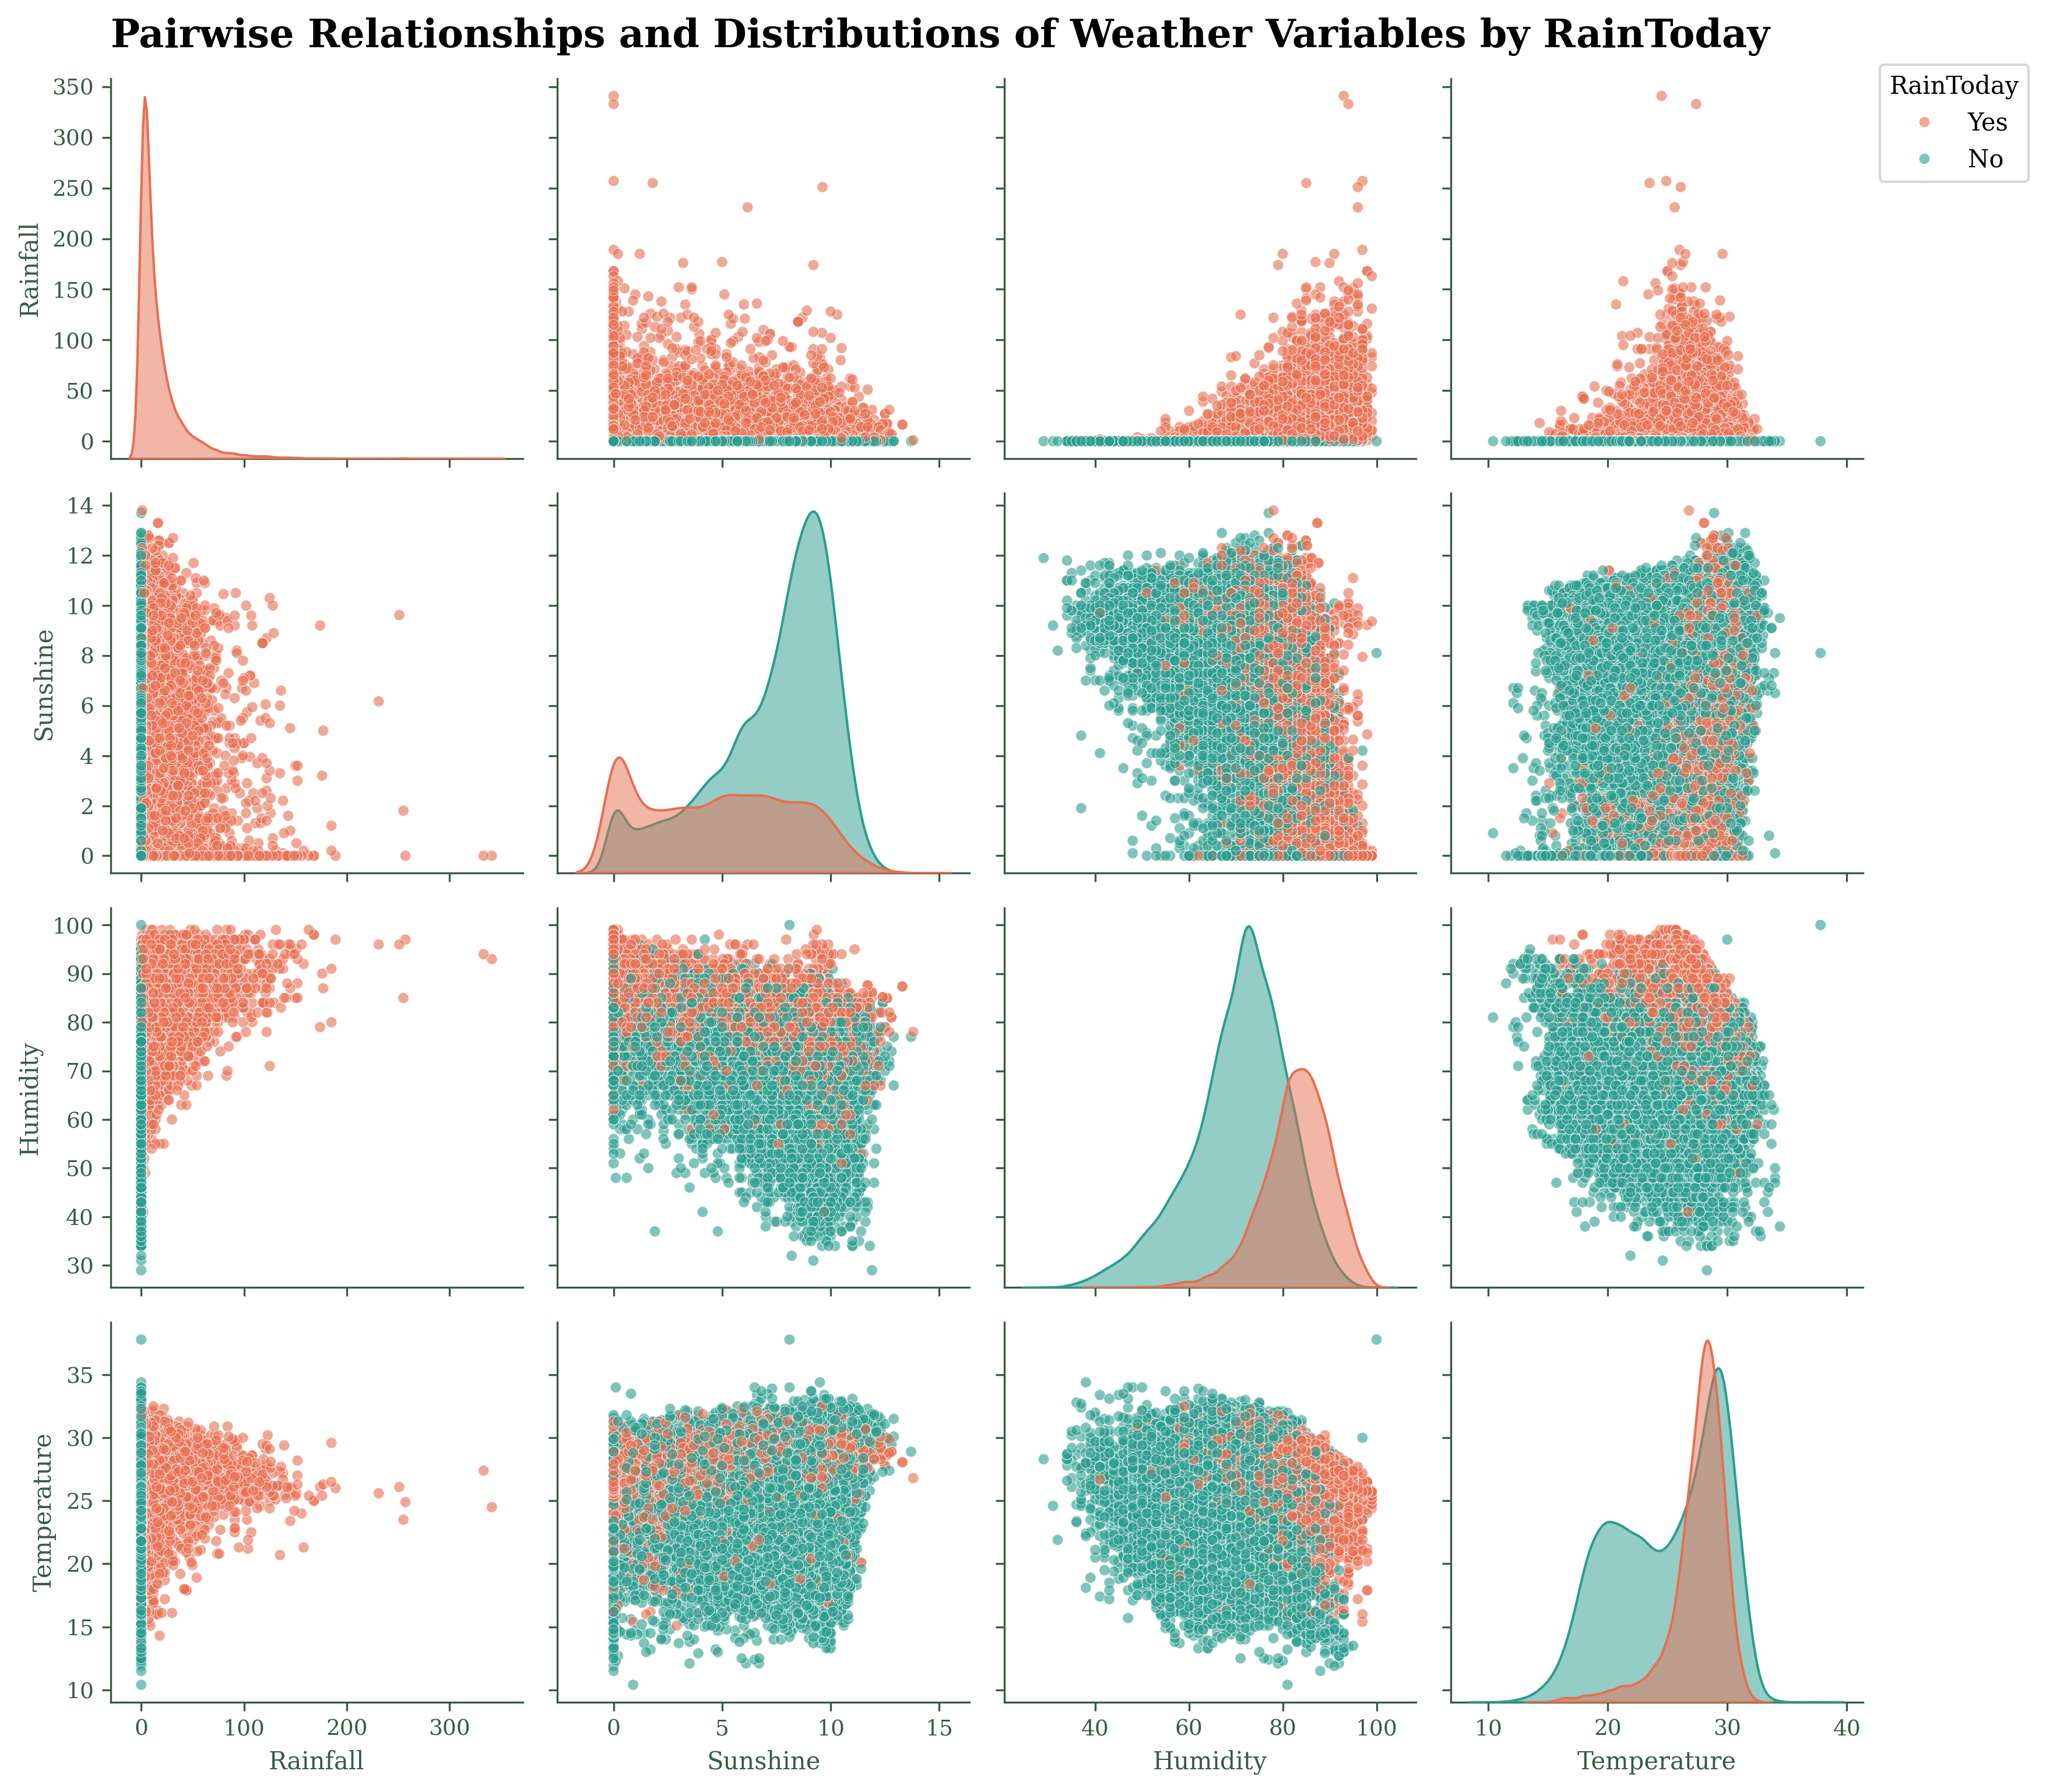

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

# Derived categorical target for hue (change condition/threshold as needed)
df['RainToday'] = df['Rainfall'].apply(lambda x: 'Yes' if x > 0 else 'No')

params = ['Rainfall', 'Sunshine', 'Humidity', 'Temperature']

mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.size'] = 10

# --- UPDATED COLOR PALETTE HERE ---
# Example: Teal (#2A9D8F) for 'No' and Coral (#E76F51) for 'Yes'
custom_palette = {'No': '#2A9D8F', 'Yes': '#E76F51'}

g = sns.pairplot(
    df[params + ['RainToday']],
    hue='RainToday',
    palette=custom_palette,
    diag_kind='kde',
    plot_kws=dict(alpha=0.6, s=20, edgecolor='white', linewidth=0.3),
    diag_kws=dict(fill=True, alpha=0.5),
    corner=False
)

g.fig.set_dpi(300)
g._legend.set_title('RainToday')
plt.tight_layout()
g.fig.suptitle(
    'Fig 7:pPairwise Relationships and Distributions of Weather Variables by RainToday',
    fontsize=16,
    fontweight='bold',
    y=1.02
)

# Move legend outside the plot area so it doesn't overlap the diagonal panels
sns.move_legend(g, "upper right", bbox_to_anchor=(1.08, 1.0), title='RainToday', frameon=True)
plt.savefig('chittagong_pairplot.png', dpi=300, bbox_inches='tight')
plt.show()